# Part D: Evaluation of the flags against the labeled events

**What this notebook does, in order**
1. Loads the flags (Part C) and the labeled events (Part A). Keeps the evaluation period (test by default) and events that are usable.
2. For every method, finds the **flagged runs**: consecutive flagged hours in one building.
3. **Event-level results:** was each labeled event found, how fast, how much of it was flagged, and were there flags right after it ended?
4. **Run-level results:** how many flagged runs touch a real event (precision), and how clean is the top of the ranked list (precision at 50 and 100)?
5. Splits everything by **event length group** and by **all labeled buildings vs Education only**.
6. Saves tidy tables and one figure for the report.

**How to read the results**
- All methods were set to the same false-alarm rate on normal *validation* hours (Part C). So the question is: at the same alarm budget, which method finds more real events?
- Unlabeled hours inside the 200 labeled buildings are treated as normal. Some of them may be real anomalies nobody labeled, so **precision may be understated**. Report it as such.
- LEAD labels were made by people looking at plots, and LEAD comes from the same source as GEPIII, so this is a check against human judgment and not against ground truth.
- The intervals shown are Wilson 95% intervals. Events inside one building are related to each other, so the intervals are a little too narrow. Treat small differences between methods as unclear.
- Do not change any setting after looking at test results. If you want to explore, set `EVAL_SPLIT = "val"`.

Run the cells in order. Cells marked **CHANGE** may need your file names.

## 0. Settings (CHANGE)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

FLAG_FILE   = "outputs/flags.parquet"                # from Part C (falls back to flags.csv.gz)
EVENT_FILE  = "outputs/lead_events.csv"              # from Part A
INFO_FILE   = "outputs/labeled_buildings_info.csv"   # from Part A
FIXED_FILE  = "outputs/cut_fixed_thresholds.csv"     # from Part C (only used to rank the fixed method)
OUT_DIR     = Path("outputs")

EVAL_SPLIT      = "test"   # "test" for the final numbers, "val" for exploring
MAX_ZERO_SHARE  = 0.5      # events mostly inside zero runs are dropped (same rule as Part A)
RUN_GAP_HOURS   = 1        # flagged hours at most this far apart belong to one run (1 = consecutive hours)
AFTER_HOURS     = 3        # "flags just after an event" = flagged hours in the next 3 hours
TOP_KS          = [50, 100]
MIN_EVENTS      = 20       # warn when a group has fewer events than this
LENGTH_LABELS   = ["1 h", "2-3 h", "4-12 h", ">12 h"]

PRETTY = {"last_hour": "Same as last hour", "typical": "Historical typical value",
          "A": "Model A (no history)", "B": "Model B (+ yesterday, last week)",
          "C": "Model C (+ previous hour)", "fixed": "Fixed percentile"}

## 1. Load flags and events

**What happens:** the flags are limited to the evaluation period. Events are kept if they start in that period and are usable (not mostly inside zero runs, and at least one valid hour). Valid hours are the hours where every predictor had a prediction and the reading was real; flags exist only on valid hours.

**What to check:** the number of events per length group, and the methods that were found.

In [2]:
def read_any(path):
    p = Path(path)
    stem = p.name.split(".")[0]
    for c in [p, p.with_name(stem + ".csv.gz"), p.with_name(stem + ".csv"), p.with_name(stem + ".parquet")]:
        if c.exists():
            print("reading", c)
            return pd.read_parquet(c) if c.suffix == ".parquet" else pd.read_csv(c)
    raise FileNotFoundError(f"Could not find {path}. Run Part C first.")

flags = read_any(FLAG_FILE)
flags["timestamp"] = pd.to_datetime(flags["timestamp"])
flags = flags[flags["split"] == EVAL_SPLIT].sort_values(["building_id", "timestamp"]).reset_index(drop=True)
flags["t"] = (flags["timestamp"] - pd.Timestamp("2016-01-01")) // pd.Timedelta(hours=1)

methods = [c[len("flag_"):] for c in flags.columns if c.startswith("flag_")]
print("methods found:", methods)
info = pd.read_csv(INFO_FILE).set_index("building_id")
flags["is_education"] = flags["building_id"].map(info["primary_use"]).eq("Education")

# rank score for ordering runs: the error score for model methods, reading / threshold for the fixed method
for m in methods:
    if m != "fixed":
        flags["rank_" + m] = flags["score_" + m]
if "fixed" in methods:
    if Path(FIXED_FILE).exists():
        thr = pd.read_csv(FIXED_FILE, index_col="building_id")["fixed_threshold"]
        flags["rank_fixed"] = flags["actual"] / flags["building_id"].map(thr)
    else:
        flags["rank_fixed"] = np.nan
        print("fixed thresholds file not found: precision at top K will be empty for the fixed method")

ev = pd.read_csv(EVENT_FILE, parse_dates=["start", "end"])
ev["split"] = ev["split"].replace({"validation": "val"})
n_all = (ev["split"] == EVAL_SPLIT).sum()
ev = ev[(ev["split"] == EVAL_SPLIT) & (ev["zero_share"] <= MAX_ZERO_SHARE)].copy()
ev = ev[ev["building_id"].isin(flags["building_id"].unique())]
ev["s"] = (ev["start"] - pd.Timestamp("2016-01-01")) // pd.Timedelta(hours=1)
ev["e"] = (ev["end"] - pd.Timestamp("2016-01-01")) // pd.Timedelta(hours=1)

def times_by_building(frame, mask):
    sub = frame[mask]
    return {b: g["t"].to_numpy() for b, g in sub.groupby("building_id")}

def count_in(times, b, lo_t, hi_t):
    t = times.get(b)
    if t is None:
        return 0
    return int(np.searchsorted(t, hi_t, "right") - np.searchsorted(t, lo_t, "left"))

valid_times = times_by_building(flags, flags["valid"])
ev["n_valid"] = [count_in(valid_times, b, s, e) for b, s, e in zip(ev["building_id"], ev["s"], ev["e"])]
dropped_valid = int((ev["n_valid"] == 0).sum())
ev = ev[ev["n_valid"] > 0].reset_index(drop=True)
ev["length_group"] = pd.Categorical(ev["length_group"], LENGTH_LABELS, ordered=True)

print(f"evaluation split: {EVAL_SPLIT}")
print(f"events in split: {n_all} | usable: {len(ev)} | dropped for zero runs or no valid hours: {n_all - len(ev)}")
print()
print(pd.crosstab(ev["length_group"], ev["is_education"].map({True: "Education", False: "Other"}), margins=True).to_string())
small = ev.groupby("length_group", observed=True).size()
small = small[small < MIN_EVENTS]
if len(small):
    print("\nWARNING: fewer than", MIN_EVENTS, "events in:", list(small.index), "- treat those rows as unclear")

reading outputs/flags.parquet
methods found: ['last_hour', 'typical', 'A', 'B', 'C', 'fixed']
evaluation split: test
events in split: 647 | usable: 587 | dropped for zero runs or no valid hours: 60

is_education  Education  Other  All
length_group                       
1 h                  59    153  212
2-3 h                30     62   92
4-12 h               48    137  185
>12 h                36     62   98
All                 173    414  587


## 2. Event-level results

**What happens:** for each method and each labeled event, the notebook records
- **found:** at least one flagged hour inside the event,
- **delay:** hours from the event start to its first flag (only for found events),
- **hour share:** the share of the event's valid hours that were flagged,
- **flag after:** at least one flagged hour in the `AFTER_HOURS` hours after the event ends (can point to late or lingering detection).

An event can be found by a single flagged hour, so recall is a generous measure. The hour share shows how fully the event is covered.

In [3]:
def event_results(method):
    times = times_by_building(flags, flags["flag_" + method])
    found, delay, nfl, aft = [], [], [], []
    for b, s, e in zip(ev["building_id"], ev["s"], ev["e"]):
        t = times.get(b)
        if t is None:
            found.append(False); delay.append(np.nan); nfl.append(0); aft.append(False)
            continue
        lo = np.searchsorted(t, s, "left")
        hi = np.searchsorted(t, e, "right")
        n = hi - lo
        found.append(n > 0)
        delay.append(float(t[lo] - s) if n > 0 else np.nan)
        nfl.append(int(n))
        aft.append(bool(np.searchsorted(t, e + AFTER_HOURS, "right") - hi > 0))
    out = pd.DataFrame({"found": found, "delay": delay, "n_flagged": nfl, "flag_after": aft}, index=ev.index)
    out["hour_share"] = out["n_flagged"] / ev["n_valid"]
    return out

ev_res = {m: event_results(m) for m in methods}
print("done:", {m: int(r["found"].sum()) for m, r in ev_res.items()}, "events found out of", len(ev))

done: {'last_hour': 171, 'typical': 8, 'A': 9, 'B': 20, 'C': 170, 'fixed': 42} events found out of 587


## 3. Flagged runs and run-level results

**What happens:** consecutive flagged hours in one building form a **run**. A run is a *hit* if at least one of its hours is labeled as an anomaly. 
- **Run precision** = hits divided by runs.
- **Precision at K** = among the K runs with the highest top score (across all buildings), the share that are hits. This is the "ranked list worth a human check" from the project definition.

Scores are scaled per building, so they can be compared across buildings. For the fixed method the ranking uses reading divided by threshold, which is less comparable, so read its top-K numbers with that in mind.

In [4]:
def make_runs(method):
    sub = flags[flags["flag_" + method]].copy()
    if sub.empty:
        return pd.DataFrame(columns=["building_id", "start", "end", "hours", "hit", "max_rank", "is_education"])
    gap = sub.groupby("building_id")["t"].diff()
    sub["run_id"] = (gap.isna() | (gap > RUN_GAP_HOURS)).cumsum()
    runs = sub.groupby("run_id").agg(building_id=("building_id", "first"), start=("t", "min"), end=("t", "max"),
                                     hours=("t", "size"), hit=("label", "max"),
                                     max_rank=("rank_" + method, "max"),
                                     is_education=("is_education", "first"))
    runs["hit"] = runs["hit"].astype(bool)
    return runs

runs = {m: make_runs(m) for m in methods}
print({m: len(r) for m, r in runs.items()}, "flagged runs")

{'last_hour': 976, 'typical': 57, 'A': 65, 'B': 74, 'C': 886, 'fixed': 1040} flagged runs


## 4. Summary table: every method, all buildings and Education only

**What happens:** one row per method and scope with the main numbers. The false-alarm column shows the share of normal hours (valid, unlabeled) that were flagged in the evaluation period. It was fixed on validation, so a different value here shows how stable the cut-off is.

In [5]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (c - h, c + h)

def summarize(scope):
    rows = []
    for m in methods:
        r = ev_res[m]
        em = np.ones(len(ev), bool) if scope == "All labeled buildings" else ev["is_education"].to_numpy()
        n = int(em.sum()); k = int(r.loc[em, "found"].sum())
        lo, hi = wilson(k, n)
        ru = runs[m]
        ru = ru if scope == "All labeled buildings" else ru[ru["is_education"]]
        fm = flags["is_education"] if scope != "All labeled buildings" else pd.Series(True, index=flags.index)
        normal = flags[fm & flags["valid"] & (flags["label"] == 0)]
        row = {"method": PRETTY.get(m, m), "scope": scope, "events": n, "events_found": k,
               "recall": k / n if n else np.nan, "recall_low": lo, "recall_high": hi,
               "median_delay_h": r.loc[em & r["found"].to_numpy(), "delay"].median(),
               "hour_share": r.loc[em, "hour_share"].mean(),
               "flag_after_share": r.loc[em, "flag_after"].mean(),
               "runs": len(ru), "run_precision": ru["hit"].mean() if len(ru) else np.nan,
               "false_alarm_pct": normal["flag_" + m].mean() * 100}
        for K in TOP_KS:
            top = ru.sort_values("max_rank", ascending=False).head(K)
            row[f"precision_at_{K}"] = top["hit"].mean() if len(top) else np.nan
            row[f"runs_in_top_{K}"] = len(top)
        rows.append(row)
    return pd.DataFrame(rows)

summary = pd.concat([summarize("All labeled buildings"), summarize("Education only")], ignore_index=True)
show = summary.copy()
for c in ["recall", "recall_low", "recall_high", "hour_share", "flag_after_share", "run_precision"] + [f"precision_at_{K}" for K in TOP_KS]:
    show[c] = (show[c] * 100).round(1)
show["median_delay_h"] = show["median_delay_h"].round(1)
show["false_alarm_pct"] = show["false_alarm_pct"].round(2)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print("Percent values. Recall is shown with its 95% interval.")
print(show.to_string(index=False))

Percent values. Recall is shown with its 95% interval.
                          method                 scope  events  events_found  recall  recall_low  recall_high  median_delay_h  hour_share  flag_after_share  runs  run_precision  false_alarm_pct  precision_at_50  runs_in_top_50  precision_at_100  runs_in_top_100
               Same as last hour All labeled buildings     587           171    29.1        25.6         32.9             0.0        18.0              22.8   976           18.5             0.35             54.0              50              53.0              100
        Historical typical value All labeled buildings     587             8     1.4         0.7          2.7             0.0         0.8               5.8    57           14.0             0.08             14.0              50              14.0               57
            Model A (no history) All labeled buildings     587             9     1.5         0.8          2.9             1.0         1.1               6.3    

## 5. Recall by event length group

**What happens:** the same event recall, split into 1 h, 2-3 h, 4-12 h and over 12 h events, for each method and scope. This is where design choices should show: short events are the hardest to separate from normal noise, and a history-aware predictor should help most there.

Rows with fewer than `MIN_EVENTS` events are marked so they are not over-read.

In [6]:
rows = []
for scope in ["All labeled buildings", "Education only"]:
    em = np.ones(len(ev), bool) if scope == "All labeled buildings" else ev["is_education"].to_numpy()
    for lg in LENGTH_LABELS:
        gm = em & (ev["length_group"] == lg).to_numpy()
        n = int(gm.sum())
        for m in methods:
            r = ev_res[m]
            k = int(r.loc[gm, "found"].sum())
            lo, hi = wilson(k, n)
            rows.append({"scope": scope, "length_group": lg, "method": PRETTY.get(m, m), "events": n, "found": k,
                         "recall_pct": round(100 * k / n, 1) if n else np.nan,
                         "low_pct": round(100 * lo, 1) if n else np.nan, "high_pct": round(100 * hi, 1) if n else np.nan,
                         "hour_share_pct": round(100 * r.loc[gm, "hour_share"].mean(), 1) if n else np.nan,
                         "few_events": n < MIN_EVENTS})
by_len = pd.DataFrame(rows)
for scope in ["All labeled buildings", "Education only"]:
    print(scope, "- recall % (events in brackets)")
    sub = by_len[by_len["scope"] == scope]
    tab = sub.pivot(index="method", columns="length_group", values="recall_pct")[LENGTH_LABELS]
    cnt = sub[sub["method"] == sub["method"].iloc[0]].set_index("length_group")["events"]
    tab.columns = [f"{c} (n={cnt[c]})" for c in LENGTH_LABELS]
    print(tab.reindex([PRETTY.get(m, m) for m in methods]).to_string())
    print()

All labeled buildings - recall % (events in brackets)
                                  1 h (n=212)  2-3 h (n=92)  4-12 h (n=185)  >12 h (n=98)
method                                                                                   
Same as last hour                        36.3          37.0            17.3          28.6
Historical typical value                  0.0           0.0             0.5           7.1
Model A (no history)                      0.0           0.0             0.0           9.2
Model B (+ yesterday, last week)          0.0           0.0             1.1          18.4
Model C (+ previous hour)                24.5          38.0            22.7          41.8
Fixed percentile                          4.7           6.5             9.2           9.2

Education only - recall % (events in brackets)
                                  1 h (n=59)  2-3 h (n=30)  4-12 h (n=48)  >12 h (n=36)
method                                                                                 
Sa

## 6. Save the tables and a figure

**What happens:** the two tables and a figure of recall by length group are saved in `outputs`, ready to drop into the report. The file names include the evaluation split so test and validation results do not overwrite each other.

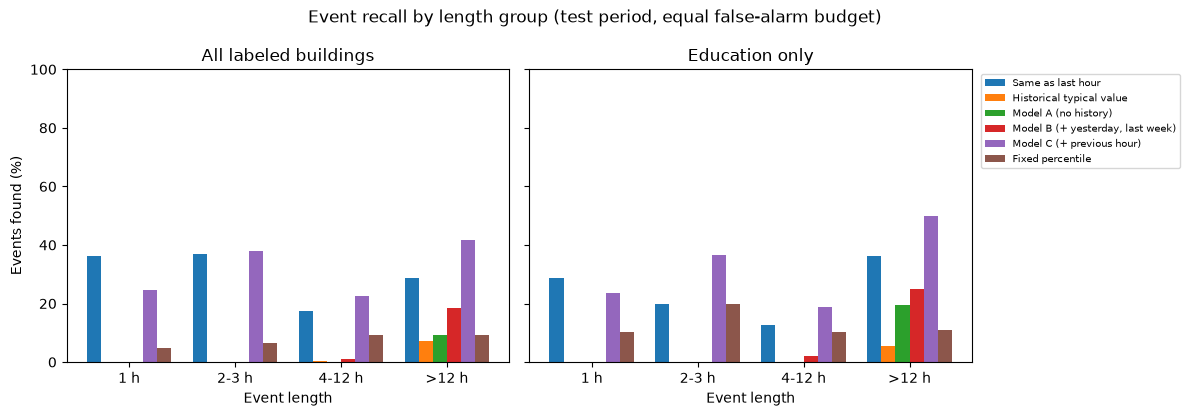

saved: eval_summary_test.csv, eval_by_length_test.csv, eval_recall_by_length_test.png


In [7]:
import matplotlib.pyplot as plt

tag = EVAL_SPLIT
summary.to_csv(OUT_DIR / f"eval_summary_{tag}.csv", index=False)
by_len.to_csv(OUT_DIR / f"eval_by_length_{tag}.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, scope in zip(axes, ["All labeled buildings", "Education only"]):
    sub = by_len[by_len["scope"] == scope]
    width = 0.8 / len(methods)
    for i, m in enumerate(methods):
        s = sub[sub["method"] == PRETTY.get(m, m)].set_index("length_group").reindex(LENGTH_LABELS)
        ax.bar(np.arange(len(LENGTH_LABELS)) + i * width, s["recall_pct"], width, label=PRETTY.get(m, m))
    ax.set_xticks(np.arange(len(LENGTH_LABELS)) + width * (len(methods) - 1) / 2)
    ax.set_xticklabels(LENGTH_LABELS)
    ax.set_title(scope)
    ax.set_xlabel("Event length")
axes[0].set_ylabel("Events found (%)")
axes[0].set_ylim(0, 100)
axes[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.suptitle(f"Event recall by length group ({EVAL_SPLIT} period, equal false-alarm budget)")
plt.tight_layout()
plt.savefig(OUT_DIR / f"eval_recall_by_length_{tag}.png", dpi=200, bbox_inches="tight")
plt.show()
print("saved:", f"eval_summary_{tag}.csv, eval_by_length_{tag}.csv, eval_recall_by_length_{tag}.png")

## 7. How to read and report this

1. **Start with the comparison at equal alarm budget.** Look at recall for A, B and C. If B and C are clearly above A, recent history matters. If they are close, say so: that is also a finding.
2. **Check against the simple methods.** If the same-as-last-hour baseline or the fixed percentile is close to the model, the model is not adding much for this label set. Say that directly.
3. **Look at the length groups.** Report where the methods differ and where they do not. Groups with few events are unclear.
4. **Expect the same-as-last-hour baseline to look different.** It flags the hour an event starts and the hour after it ends (because the previous hour was the anomaly), so its hour share is low and its flag-after share is high. That is a property of the method, not a bug. Judge it on recall and delay.
5. **Report precision with its caveat.** Unlabeled hours are treated as normal, so precision is probably understated.
6. **Check the false-alarm column.** If the test rate is far from the validation target for one method, that cut-off did not carry over well. Report it.
7. **Do not tune anything now.** Cut-offs, features and settings were fixed before looking at test results. Anything you change after this must be described as a new version.

Negative or inconclusive results are acceptable for the midterm as long as they are checked and explained.

**Next:** Part E, the planned experiments (feature sets, detector comparison, optional synthetic injection), and Part F, the figures for the report and slides.